In [1]:
# Instalacija fastai biblioteke
!pip install -Uqq fastai

from fastai.vision.all import *

# Preuzimanje Oxford-IIIT Pet dataseta
path = untar_data(URLs.PETS)

# Prikaz sadržaja dataseta
path.ls()

<div><progress max="811706944" value="811712512"></progress> 100.00% [811712512/811706944 00:18&lt;00:00]</div>

[Path('/root/.fastai/data/oxford-iiit-pet/annotations'), Path('/root/.fastai/data/oxford-iiit-pet/images')]

In [2]:
files = get_image_files(path / "images")

print("Broj slika:", len(files))

Broj slika: 7390


In [3]:
def label_func(f):
    return f[0].isupper()

In [4]:
dls = ImageDataLoaders.from_name_func(
    path,
    files,
    label_func,
    item_tfms=Resize(224)
)

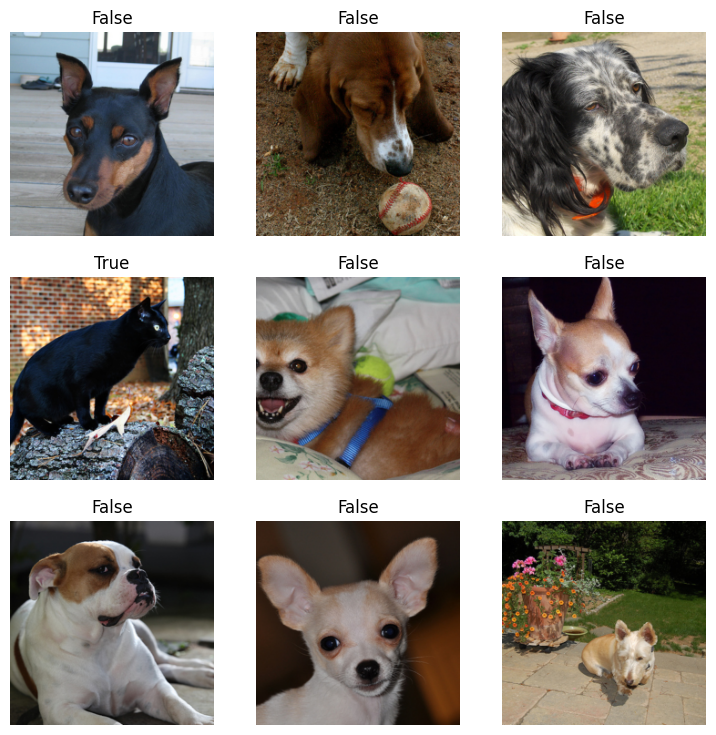

In [5]:
dls.show_batch()

In [6]:
learn = cnn_learner(
    dls,
    resnet34,
    metrics=error_rate
)

learn.fine_tune(1)

/usr/local/lib/python3.13/dist-packages/fastai/vision/learner.py:304: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:01<00:00, 81.8MB/s]


epoch,train_loss,valid_loss,error_rate,time


epoch,train_loss,valid_loss,error_rate,time


KeyboardInterrupt: 

In [ ]:
learn.predict(files[0])

In [ ]:
learn.show_results()

In [ ]:
from fastai.vision.all import *
import pandas as pd

path = untar_data(URLs.PASCAL_2007)

path.ls()

In [ ]:
df = pd.read_csv(path / "train.csv")

df.head()

In [ ]:
dls = ImageDataLoaders.from_df(
    df,
    path,
    folder='train',
    valid_col='is_valid',
    label_delim=' ',
    item_tfms=Resize(460),
    batch_tfms=aug_transforms(size=224)
)

In [ ]:
dls.show_batch()

In [ ]:
learn = cnn_learner(
    dls,
    resnet50,
    metrics=partial(accuracy_multi, thresh=0.5)
)

In [ ]:
learn.lr_find()

<div><div><progress max="2" value="0"></progress> 0.00% [0/2 00:00&lt;?]</div><div></div><div><progress max="92" value="16"></progress> 17.39% [16/92 06:19&lt;30:04... 0.8732]</div></div>

In [ ]:
learn.fine_tune(2, 3e-2)
learn.show_results()

In [ ]:
learn.predict(path / 'train/000005.jpg')

In [ ]:
interp = Interpretation.from_learner(learn)

interp.plot_top_losses(9)